# Laboratorio 3 · Caja de herramientas de anonimización

**Atacar → Medir → Transformar → Comparar → Decidir → Entregar**

Leyes, Ética y Protección de Datos · Especialización en Análisis Estadístico para Ciencia de Datos · Docente: Wilson Sandoval Rodríguez

---

> **Versión con soluciones.** Material de apoyo docente. Incluye respuestas orientativas y las celdas ya ejecutadas.

> Todos los datos son **sintéticos**. Ninguna persona real está representada.


## «Anonimícenla y se la mandamos el viernes»

El proveedor del motor de recomendación pide la base de DataMarket. En este
laboratorio usted va a hacer **lo que casi nadie hace antes de entregar una
base**: atacarla, medirla, transformarla con varias técnicas y decidir con
números.

| | |
|:--|:--|
| **Aprenderá a** | Aplicar ocho técnicas de protección, medir el riesgo y la utilidad que deja cada una, y sostener una decisión de entrega |
| **Duración** | 45 minutos en clase · se termina en la Actividad 4 |
| **Evidencia** | Bitácora de técnicas, gráfico riesgo-utilidad, base entregable e informe generado |
| **Unidad** | 3 · Técnicas de protección, IA y datos masivos |

### Mapa del laboratorio

| Parte | Qué pasa | Tiempo |
|:--|:--|:--:|
| **0 · Preparar** | Cargar datos y la caja de herramientas | 2 min |
| **1 · Atacar** | Reidentificamos clientes con una sola línea de código | 8 min |
| **2 · Medir** | *k*-anonimato, *l*-diversidad y probabilidad de reidentificación | 7 min |
| **3 · Transformar** | Ocho estaciones, una técnica por estación | 18 min |
| **4 · Comparar** | La frontera riesgo-utilidad y el ataque repetido | 5 min |
| **5 · Decidir y entregar** | Base entregable + informe automático | 5 min |
| **6 · Reflexionar** | Big Data, IA y una regla para el decálogo | — |

> 🎛️ Las celdas marcadas con **PERILLA** tienen parámetros para mover. Cámbielos,
> vuelva a ejecutar y mire qué pasa. Ese es el laboratorio.

---

# 0 · PREPARAR

In [1]:
from pathlib import Path
import pandas as pd

# Funciona en tres sitios sin cambiar nada:
#   - dentro del repositorio (labs/ o raíz)
#   - en Google Colab
#   - en cualquier equipo con internet
RUTA = Path("../data/clientes_sinteticos.csv")
if not RUTA.exists():
    RUTA = Path("data/clientes_sinteticos.csv")
if not RUTA.exists():
    RUTA = "https://raw.githubusercontent.com/wilsonsr/leyes-etica-proteccion-datos/main/data/clientes_sinteticos.csv"

print("Origen de los datos:", RUTA)

Origen de los datos: ../data/clientes_sinteticos.csv


In [2]:
import hashlib
import hmac
import secrets
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

df = pd.read_csv(RUTA)
# Recencia en días: más útil para el modelo que una fecha.
df["recencia_dias"] = (
    pd.to_datetime(df["fecha_ultima_compra"]).max() - pd.to_datetime(df["fecha_ultima_compra"])
).dt.days

print(f"Registros: {len(df):,}   Variables: {df.shape[1]}")
df.head(3)

Registros: 1,512   Variables: 36


,cliente_id,nombre,email,telefono,documento,fecha_nacimiento,edad,sexo,ciudad,barrio,direccion,latitud,longitud,estrato,ocupacion,ingresos_mensuales,dispositivo,ip,pais_residencia,canal_adquisicion,origen_dato,fecha_autorizacion,consentimiento_marketing,visitas_web,productos_vistos,categoria_top,compras_6m,monto_compras,fecha_ultima_compra,compras_farmacia_6m,entrega_asistida,busquedas_maternidad,score_riesgo_interno,segmento,churn,recencia_dias
0,DM-00865,Luis Castro,luis.castro806@mail.co,3361052437,SYN-92480821,1992-12-31,33,M,Barranquilla,Simon Bolivar,Carrera 7 # 58-18,10.97607,-74.80194,2.0,Pensionado/a,2460000.0,Android,135.169.205.166,Colombia,email_marketing,lista_comprada_tercero,NaN,0,12,36,moda,2,418000.0,2026-08-29,0,0,0,26,fiel,0,1
1,DM-00714,Paula Beltran,paula.beltran226@correo.com,3552777695,SYN-95884611,1974-01-01,52,F,Cartagena,Manga,Carrera 53 # 50-88,10.33459,-75.45909,1.0,Comerciante,1710000.0,iOS,192.175.234.41,Colombia,publicidad_pagada,registro_cuenta,2024-02-23,1,9,28,supermercado,4,778000.0,2026-05-11,1,0,0,48,estable,0,111
2,DM-00572,Alvaro Riveros,alvaro.riveros457@mail.co,3693537285,SYN-35266492,2000-12-31,25,F,Barranquilla,El Prado,Diagonal 42 # 18-58,10.95000,-74.77236,3.0,Comerciante,2950000.0,Android,57.79.150.169,Alemania,publicidad_pagada,programa_fidelizacion,2025-05-14,1,12,19,tecnologia,2,435000.0,2026-07-26,0,0,0,41,estable,0,35


### La caja de herramientas

La celda siguiente define todas las funciones del laboratorio. **No necesita
modificarla**, pero vale la pena leerla: son unas 120 líneas y ninguna es magia.

| Función | Para qué sirve |
|:--|:--|
| `perfil_riesgo()` | Mide *k* mínimo, % de registros con *k*=1 y *k*<5, probabilidad media de reidentificación y *l*-diversidad |
| `grafico_grupos()` | Dibuja cuántos registros quedan en grupos de tamaño 1, 2, 3–4, 5–9 y 10+ |
| `ataque_vinculacion()` | Cruza una fuente pública con la base liberada y cuenta a quién reidentifica |
| `auc_churn()` | Mide la utilidad: AUC del modelo de abandono con validación cruzada |
| `generalizar()` | Aplica generalización a edad, sexo, ciudad y ocupación con perillas |
| `registrar()` | Anota cada paso en la **bitácora** que alimenta el informe final |

In [3]:
# ===================== CAJA DE HERRAMIENTAS · no necesita modificarla =====================
COLOR = {"antes": "#94a3b8", "despues": "#0891b2", "alerta": "#dc2626",
         "ok": "#16a34a", "acento": "#7c3aed", "ambar": "#d97706"}
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "font.size": 10})

CUASI = ["edad", "sexo", "ciudad", "ocupacion"]   # lo que un atacante puede saber
SENSIBLE = "categoria_top"                         # lo que no queremos revelar
K_OBJETIVO = 5                                     # umbral de referencia del curso


def tam_grupo(datos, cuasi):
    # Tamaño del grupo de equivalencia al que pertenece cada registro.
    return datos.assign(_u=1).groupby(cuasi, dropna=False, observed=True)["_u"].transform("size")


def perfil_riesgo(datos, cuasi=CUASI, sensible=SENSIBLE, k=K_OBJETIVO):
    tam = tam_grupo(datos, cuasi)
    res = {
        "registros": len(datos),
        "combinaciones": int(datos.groupby(cuasi, dropna=False, observed=True).ngroups),
        "k mínimo": int(tam.min()),
        "% k=1": round((tam == 1).mean() * 100, 1),
        f"% k<{k}": round((tam < k).mean() * 100, 1),
        "prob. media reid. %": round((1 / tam).mean() * 100, 1),
    }
    if sensible is not None and sensible in datos.columns:
        l = datos.groupby(cuasi, dropna=False, observed=True)[sensible].transform("nunique")
        res["l mínimo"] = int(l.min())
        # Grupos con k>=2 donde todos comparten el valor sensible: identidad protegida, atributo expuesto.
        res["% homogéneos (k≥2)"] = round(((l == 1) & (tam >= 2)).mean() * 100, 1)
    return res


def grafico_grupos(versiones, cuasi_por_version=None, titulo="¿En qué tamaño de grupo queda cada persona?"):
    cortes = [0, 1, 2, 4, 9, np.inf]
    etiquetas = ["k=1\n(sola)", "k=2", "k=3–4", "k=5–9", "k≥10"]
    fig, ax = plt.subplots()
    ancho = 0.8 / len(versiones)
    paleta = [COLOR["antes"], COLOR["despues"], COLOR["acento"], COLOR["ambar"], COLOR["ok"]]
    for i, (nombre, datos) in enumerate(versiones.items()):
        cu = (cuasi_por_version or {}).get(nombre, CUASI)
        tam = tam_grupo(datos, cu)
        pct = pd.cut(tam, cortes, labels=etiquetas).value_counts(normalize=True).reindex(etiquetas) * 100
        x = np.arange(len(etiquetas)) + i * ancho - 0.4 + ancho / 2
        barras = ax.bar(x, pct.values, ancho, label=nombre, color=paleta[i % len(paleta)])
        ax.bar_label(barras, fmt="%.0f%%", fontsize=8, padding=2)
    ax.axvspan(-0.5, 2.5, color=COLOR["alerta"], alpha=0.06)
    ax.text(1, ax.get_ylim()[1] * 0.92, "zona de riesgo (k<5)", ha="center", color=COLOR["alerta"], fontsize=9)
    ax.set_xticks(range(len(etiquetas)), etiquetas)
    ax.set_ylabel("% de registros")
    ax.set_title(titulo)
    ax.legend(frameon=False)
    plt.show()


def ataque_vinculacion(publica, liberada, claves, mostrar=True):
    # publica: nombre + claves (+ _verdad solo para verificar el experimento).
    # liberada: claves + lo que se entregó (+ _verdad, que el atacante NO ve).
    publica = publica.reset_index(drop=True).rename_axis("_pid").reset_index()
    cruce = publica.merge(liberada, on=claves, how="inner", suffixes=("_pub", "_lib"))
    candidatos = cruce.groupby("_pid")["_verdad_lib"].transform("size")
    unicos = cruce[candidatos == 1]
    aciertos = unicos[unicos["_verdad_pub"] == unicos["_verdad_lib"]]
    tam = publica.merge(liberada.groupby(claves, dropna=False).size().rename("k").reset_index(),
                        on=claves, how="left")["k"]
    prob = (1 / tam).fillna(0).mean() * 100
    res = {"personas en la fuente pública": len(publica),
           "reidentificadas con certeza": len(aciertos),
           "% reidentificadas": round(len(aciertos) / len(publica) * 100, 1),
           "prob. media de acierto %": round(prob, 1)}
    if mostrar:
        print("ATAQUE DE VINCULACIÓN")
        for k_, v_ in res.items():
            print(f"  {k_:<32}: {v_}")
    return res, aciertos


def auc_churn(datos, columnas, objetivo="churn", semilla=42):
    X = pd.get_dummies(datos[columnas].copy(), drop_first=False, dtype=float)
    X = X.fillna(X.median(numeric_only=True))
    y = datos[objetivo]
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
    cv = StratifiedKFold(5, shuffle=True, random_state=semilla)
    return round(float(cross_val_score(modelo, X, y, cv=cv, scoring="roc_auc").mean()), 3)


REGIONES = {
    "Bogota": "Centro", "Ibague": "Centro", "Villavicencio": "Centro",
    "Medellin": "Antioquia-Eje", "Pereira": "Antioquia-Eje", "Manizales": "Antioquia-Eje",
    "Cali": "Pacífico", "Pasto": "Pacífico",
    "Barranquilla": "Caribe", "Cartagena": "Caribe", "Santa Marta": "Caribe",
    "Bucaramanga": "Nororiente",
}
GRUPOS_OCUPACION = {
    "Ingeniero/a": "técnico-profesional", "Tecnico/a": "técnico-profesional",
    "Disenador/a": "técnico-profesional", "Contador/a": "técnico-profesional",
    "Abogado/a": "técnico-profesional", "Administrador/a": "técnico-profesional",
    "Docente": "servicios", "Enfermero/a": "servicios",
    "Comerciante": "servicios", "Independiente": "servicios",
    "Estudiante": "sin actividad remunerada", "Pensionado/a": "sin actividad remunerada",
}


def generalizar(datos, edad=10, sexo="agrupar", ciudad="region", ocupacion="grupo"):
    # edad: 0 (exacta), 5, 10 o 20 años  ·  sexo: "conservar" | "agrupar" | "suprimir"
    # ciudad: "ciudad" | "region" | "suprimir"  ·  ocupacion: "exacta" | "grupo" | "suprimir"
    d = datos.copy()
    if edad:
        ini = (d["edad"] // edad * edad).astype(int)
        d["edad"] = ini.astype(str) + "–" + (ini + edad - 1).astype(str)
    if sexo == "agrupar":
        d["sexo"] = d["sexo"].replace({"Otro": "Otro/NR", "Prefiere no responder": "Otro/NR"})
    elif sexo == "suprimir":
        d["sexo"] = "*"
    if ciudad == "region":
        d["ciudad"] = d["ciudad"].map(REGIONES)
    elif ciudad == "suprimir":
        d["ciudad"] = "*"
    if ocupacion == "grupo":
        d["ocupacion"] = d["ocupacion"].map(GRUPOS_OCUPACION)
    elif ocupacion == "suprimir":
        d["ocupacion"] = "*"
    return d


BITACORA = []


def registrar(paso, datos, tecnica, utilidad=None, nota=""):
    fila = {"paso": paso, "técnica": tecnica, **perfil_riesgo(datos)}
    if utilidad is not None:
        fila["AUC"] = utilidad
    fila["nota"] = nota
    BITACORA[:] = [b for b in BITACORA if b["paso"] != paso] + [fila]
    return pd.DataFrame(BITACORA).set_index("paso")


print("Caja de herramientas lista ✔")

Caja de herramientas lista ✔


---

# 1 · ATACAR

*Antes de proteger una base, intente romperla.*

### La versión «anonimizada» que casi todo el mundo entrega

Borramos nombre, correo, teléfono, documento y dirección. Es lo que se suele
llamar «anonimizar».

In [4]:
IDENTIFICADORES_DIRECTOS = ["nombre", "email", "telefono", "documento", "direccion"]

base_ingenua = df.drop(columns=IDENTIFICADORES_DIRECTOS).copy()
base_ingenua["_verdad"] = df["cliente_id"]   # solo para verificar el experimento

print(f"Quedan {base_ingenua.shape[1] - 1} variables. Ningún nombre a la vista.")
base_ingenua[CUASI + ["compras_farmacia_6m", "busquedas_maternidad", "categoria_top"]].head()

Quedan 31 variables. Ningún nombre a la vista.


,edad,sexo,ciudad,ocupacion,compras_farmacia_6m,busquedas_maternidad,categoria_top
0,33,M,Barranquilla,Pensionado/a,0,0,moda
1,52,F,Cartagena,Comerciante,1,0,supermercado
2,25,F,Barranquilla,Comerciante,0,0,tecnologia
3,37,F,Bucaramanga,Pensionado/a,0,0,moda
4,58,M,Pereira,Disenador/a,4,0,tecnologia


### El atacante

Alguien tiene una **fuente pública**: perfiles profesionales, una lista de
egresados, una publicación en redes. En ella aparecen 300 clientes con su
nombre, edad, sexo, ciudad y ocupación. Nada secreto.

In [5]:
rng = np.random.default_rng(2026)
muestra = rng.choice(len(df), size=300, replace=False)

fuente_publica = df.iloc[muestra][["nombre"] + CUASI].copy()
fuente_publica["_verdad"] = df.iloc[muestra]["cliente_id"].values   # el atacante no lo ve

fuente_publica.drop(columns="_verdad").head()

,nombre,edad,sexo,ciudad,ocupacion
1465,Carlos Peralta,41,M,Bogota,Enfermero/a
1414,Santiago Moreno,32,F,Cali,Tecnico/a
489,Tatiana Barrios,39,M,Bogota,Abogado/a
433,Mateo Solano,69,M,Bogota,Comerciante
748,Claudia Cardenas,56,F,Bucaramanga,Tecnico/a


In [6]:
# El ataque completo es esta línea:
cruce = fuente_publica.merge(base_ingenua, on=CUASI)

res_ingenua, reidentificados = ataque_vinculacion(fuente_publica, base_ingenua, CUASI)

print("\nLo que ahora sabemos de cinco personas con nombre propio:")
reidentificados[["nombre", "edad", "ciudad", "categoria_top",
                 "compras_farmacia_6m", "busquedas_maternidad", "entrega_asistida"]].head()

ATAQUE DE VINCULACIÓN
  personas en la fuente pública   : 300
  reidentificadas con certeza     : 248
  % reidentificadas               : 82.7
  prob. media de acierto %        : 91.0

Lo que ahora sabemos de cinco personas con nombre propio:


,nombre,edad,ciudad,categoria_top,compras_farmacia_6m,busquedas_maternidad,entrega_asistida
0,Carlos Peralta,41,Bogota,hogar,1,0,1
1,Santiago Moreno,32,Cali,moda,0,1,0
2,Tatiana Barrios,39,Bogota,tecnologia,1,0,0
3,Mateo Solano,69,Bogota,libros,3,0,1
8,Angela Guerrero,47,Medellin,mascotas,1,0,0


> ### 🔴 Riesgo · Pregunta 1
>
> Con una sola línea de `merge`, ¿qué porcentaje de las 300 personas quedó reidentificado **con certeza**?
>
> Mire las columnas de la derecha: `busquedas_maternidad`, `compras_farmacia_6m`, `entrega_asistida`. ¿Qué podría inferir alguien sobre esas personas? ¿Seguiría llamando «anonimizada» a esta base?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Cerca del 80 % de la fuente pública queda reidentificada con certeza (el número exacto aparece en la salida). Las columnas de la derecha permiten inferir embarazo, una condición de salud o una discapacidad: datos sensibles que nadie recogió como tales. La base **no** está anonimizada; solo está **desnominalizada**. Es el mismo mecanismo de los casos de Sweeney (1997), AOL (2006) y Netflix (2008).

</details>

**Mi respuesta:** …

---

# 2 · MEDIR

*Anonimizar es un resultado que se mide, no una operación que se aplica.*

### Tres ideas en una tabla de ocho filas

Antes de mirar 1 512 registros, mire ocho. Los **cuasi-identificadores** son
edad y ciudad; el **atributo sensible** es la categoría que más compra.

In [7]:
juguete = pd.DataFrame({
    "edad":      ["30–39", "30–39", "30–39", "40–49", "40–49", "40–49", "50–59", "50–59"],
    "ciudad":    ["Caribe", "Caribe", "Caribe", "Centro", "Centro", "Centro", "Centro", "Pacífico"],
    "categoria": ["salud", "moda", "hogar", "maternidad", "maternidad", "maternidad", "libros", "salud"],
})
juguete["k (tamaño del grupo)"] = tam_grupo(juguete, ["edad", "ciudad"])
juguete["l (valores sensibles distintos)"] = (
    juguete.groupby(["edad", "ciudad"])["categoria"].transform("nunique"))
juguete

,edad,ciudad,categoria,k (tamaño del grupo),l (valores sensibles distintos)
0,30–39,Caribe,salud,3,3
1,30–39,Caribe,moda,3,3
2,30–39,Caribe,hogar,3,3
3,40–49,Centro,maternidad,3,1
4,40–49,Centro,maternidad,3,1
5,40–49,Centro,maternidad,3,1
6,50–59,Centro,libros,1,1
7,50–59,Pacífico,salud,1,1


| Concepto | Pregunta que responde | En la tabla |
|:--|:--|:--|
| ***k*-anonimato** | ¿Con cuántas personas me confundo? | Las dos últimas filas tienen *k* = 1: están solas |
| ***l*-diversidad** | Aunque me confunda, ¿se sabe mi dato sensible? | El grupo 40–49 · Centro tiene *k* = 3 pero *l* = 1: las tres compran maternidad |
| **Probabilidad de reidentificación** | Si el atacante adivina, ¿cuánto acierta? | 1/*k*: un tercio en el grupo de tres, certeza en los de uno |

*Hay una tercera noción, la **t-cercanía**: que la distribución del atributo
sensible en cada grupo se parezca a la de toda la base. Se menciona; no se mide
en este laboratorio.*

In [8]:
linea_base = registrar("0 · sin identificadores directos", base_ingenua,
                       "supresión de 5 columnas",
                       utilidad=None, nota="lo que casi todos entregan")
linea_base

,técnica,registros,combinaciones,k mínimo,% k=1,% k<5,prob. media reid. %,l mínimo,% homogéneos (k≥2),nota
paso,,,,,,,,,,
0 · sin identificadores directos,supresión de 5 columnas,1512,1385,1,83.9,100.0,91.6,1,3.2,lo que casi todos entregan


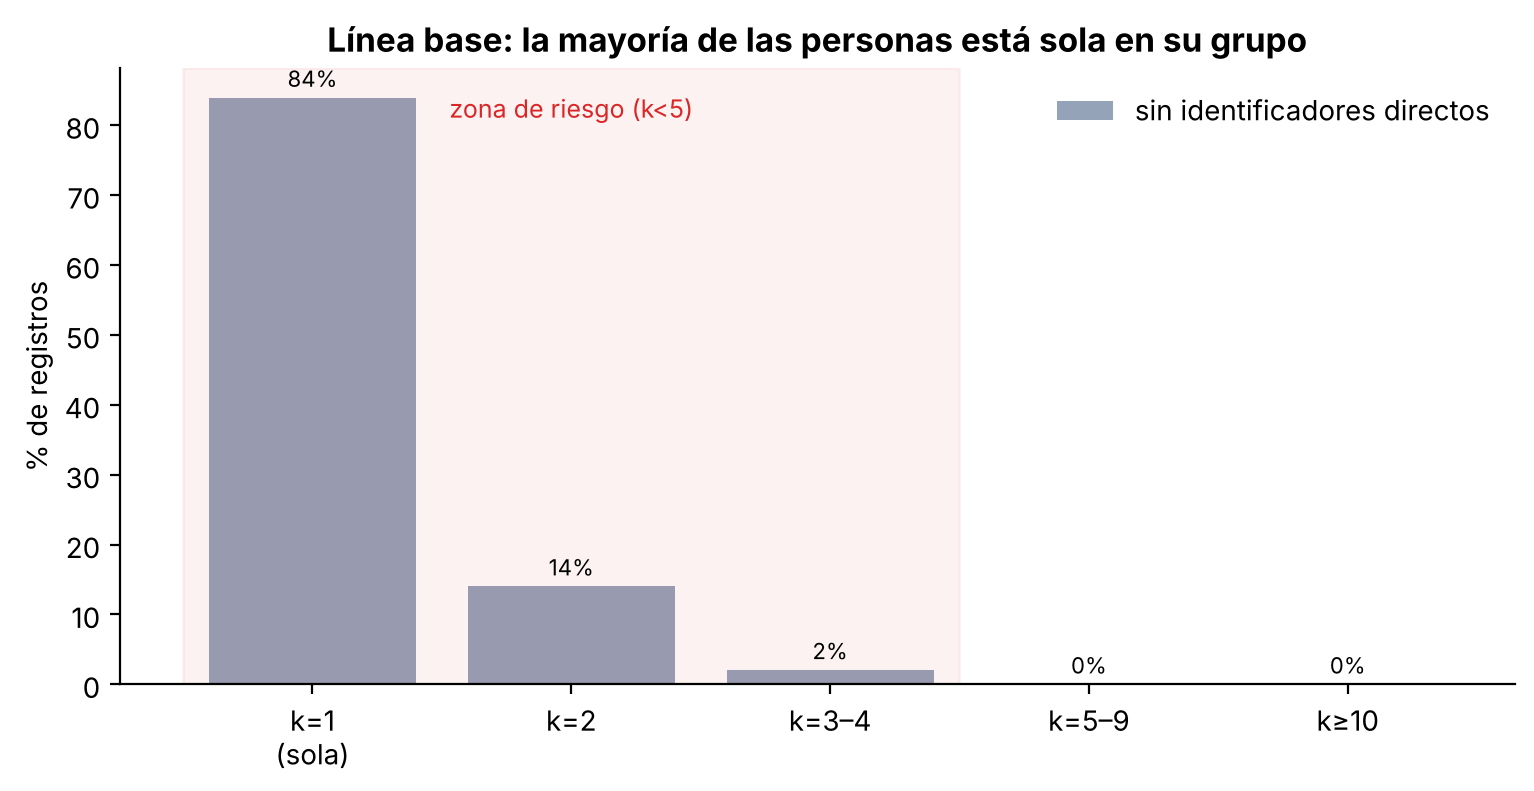

In [9]:
grafico_grupos({"sin identificadores directos": base_ingenua},
               titulo="Línea base: la mayoría de las personas está sola en su grupo")

> ### 🟡 Decida · Pregunta 2
>
> La línea base da un *k* mínimo de 1 y un porcentaje alto en *k* = 1. Ahora mire la última columna: `% homogéneos (k≥2)`.
>
> Explique con sus palabras por qué una persona puede estar **protegida en su identidad** y **expuesta en su atributo sensible** al mismo tiempo.

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Si todos los miembros de un grupo comparten el valor sensible, el atacante no necesita saber cuál de ellos es la persona: le basta con saber que está en el grupo. Es el **ataque de homogeneidad**. Por eso *k*-anonimato no basta y se mide también *l*-diversidad.

</details>

**Mi respuesta:** …

---

# 3 · TRANSFORMAR

*Ocho estaciones. En cada una: qué hace la técnica, qué protege, qué cuesta.*

| # | Estación | Familia |
|:--:|:--|:--|
| 1 | Supresión de identificadores indirectos | Eliminar |
| 2 | Seudonimización: *hash* ingenuo frente a HMAC con clave | Sustituir |
| 3 | Generalización con perillas | Reducir detalle |
| 4 | Supresión local de grupos pequeños | Eliminar |
| 5 | *Top/bottom coding* y microagregación | Reducir detalle |
| 6 | Perturbación: ruido y coordenadas | Alterar |
| 7 | Privacidad diferencial para tablas agregadas | Alterar con garantía |
| 8 | Datos sintéticos | Reemplazar |

## 🧰 Estación 1 · Supresión de identificadores indirectos

`ip`, `latitud`, `longitud` y `dispositivo` no tienen nombre, pero apuntan a
una persona o a una casa. Y el motor de recomendación no los necesita.

In [10]:
INDIRECTOS = ["ip", "latitud", "longitud", "dispositivo", "barrio", "fecha_nacimiento"]
# fecha_nacimiento es otra forma de la edad; barrio es ubicación fina.

e1 = base_ingenua.drop(columns=INDIRECTOS)
print("Columnas suprimidas:", ", ".join(INDIRECTOS))
print(f"Variables que quedan: {e1.shape[1] - 1}")

# ¿Qué habría pasado si el atacante también conociera el barrio?
for cols in [CUASI, CUASI + ["barrio"], CUASI + ["barrio", "estrato"]]:
    p = perfil_riesgo(df, cols, sensible=None)
    print(f"{' + '.join(cols):<52} -> {p['% k=1']:>5} % de personas solas")

Columnas suprimidas: ip, latitud, longitud, dispositivo, barrio, fecha_nacimiento
Variables que quedan: 25
edad + sexo + ciudad + ocupacion                     ->  83.9 % de personas solas
edad + sexo + ciudad + ocupacion + barrio            ->  94.3 % de personas solas
edad + sexo + ciudad + ocupacion + barrio + estrato  ->  97.9 % de personas solas


> ### 🟡 Decida · Pregunta 3
>
> Suprimir estas columnas **no cambia** el riesgo medido con los cuatro cuasi-identificadores. Entonces, ¿para qué sirvió?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Cierra otras puertas de ataque que la métrica con cuatro variables no ve: la IP y las coordenadas permiten vincular con registros de navegación o con un mapa; sumar `barrio` dispara la proporción de personas solas (vea la salida). La métrica mide un escenario de ataque, no todos. Por eso hay que **declarar el escenario** (qué sabe el atacante) en el informe.

</details>

**Mi respuesta:** …

## 🧰 Estación 2 · Seudonimización: el *hash* no es un escudo

El proveedor necesita una clave para unir compras del mismo cliente. Tentación:
reemplazar el documento por su *hash* SHA-256. Veamos qué pasa si alguien
tiene **otra base con documentos** (una filtración, una base comprada).

In [11]:
def hash_ingenuo(valor):
    return hashlib.sha256(str(valor).encode("utf-8")).hexdigest()[:16]

# Lo que se entrega
entrega_hash = pd.DataFrame({"id_hash": df["documento"].map(hash_ingenuo),
                             "categoria_top": df["categoria_top"]})

# Lo que tiene el atacante: 400 documentos con nombre, de otra fuente
otra_base = df.sample(400, random_state=7)[["documento", "nombre"]]
otra_base["id_hash"] = otra_base["documento"].map(hash_ingenuo)   # ¡el algoritmo es público!

revertidos = otra_base.merge(entrega_hash, on="id_hash").drop_duplicates("documento")
print(f"Hash ingenuo: {len(revertidos)} de 400 personas reidentificadas")
revertidos[["nombre", "documento", "id_hash", "categoria_top"]].head(4)

Hash ingenuo: 399 de 400 personas reidentificadas


,nombre,documento,id_hash,categoria_top
0,Natalia Trujillo,SYN-25882091,02488e0c85486338,hogar
1,Sandra Pineda,SYN-23482868,0a50dad3011fce59,tecnologia
2,Lorena Guerrero,SYN-26615928,5c0f0f845b8f9b0d,libros
3,Ximena Martinez,SYN-18242764,f286eff1087b00e5,mascotas


In [12]:
# HMAC: hash con una CLAVE SECRETA que nunca sale de DataMarket.
CLAVE_SECRETA = secrets.token_bytes(32)   # en producción: gestor de secretos, rotación, acceso por rol

def seudonimo_hmac(valor, clave=CLAVE_SECRETA):
    return hmac.new(clave, str(valor).encode("utf-8"), hashlib.sha256).hexdigest()[:16]

entrega_hmac = pd.DataFrame({"id_seudo": df["documento"].map(seudonimo_hmac),
                             "categoria_top": df["categoria_top"]})
otra_base["id_seudo"] = otra_base["documento"].map(hash_ingenuo)  # el atacante no tiene la clave
print("HMAC con clave:", otra_base.merge(entrega_hmac, on="id_seudo")["documento"].nunique(),
      "de 400 personas reidentificadas")

HMAC con clave: 0 de 400 personas reidentificadas


> ### 🔴 Riesgo · Pregunta 4
>
> Con HMAC el cruce dio cero. ¿Significa que la base seudonimizada ya es **anónima**?
>
> Piense en dos cosas: quién tiene la clave y qué pasa con los cuasi-identificadores de la parte 1.

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

No. Primero, DataMarket conserva la clave y la tabla de equivalencias: puede revertir el seudónimo, así que los datos siguen siendo personales (el GDPR lo dice expresamente en el considerando 26). Segundo, el seudónimo solo protege la columna del identificador: el ataque de vinculación por edad, sexo, ciudad y ocupación sigue funcionando igual. En 2014 se publicaron 173 millones de viajes de taxi de Nueva York con las placas «protegidas» con MD5 sin clave; se revirtieron en horas.

</details>

**Mi respuesta:** …

## 🧰 Estación 3 · Generalización con perillas 🎛️

Reducir el detalle de los cuasi-identificadores: edad exacta → rango; ciudad →
región; ocupación → grupo. **Mueva las perillas** y vuelva a ejecutar. Busque
la combinación más útil que deje menos del 5 % de los registros con *k* < 5.

In [13]:
# ===================== PERILLA =====================
NIVEL_EDAD     = 10         # 0 = exacta · 5 · 10 · 20 años
SEXO_COMO      = "agrupar"  # "conservar" · "agrupar" · "suprimir"
CIUDAD_COMO    = "region"   # "ciudad" · "region" · "suprimir"
OCUPACION_COMO = "grupo"    # "exacta" · "grupo" · "suprimir"
# ===================================================

e3 = generalizar(e1, NIVEL_EDAD, SEXO_COMO, CIUDAD_COMO, OCUPACION_COMO)
registrar("3 · generalización (mía)", e3, "generalización",
          nota=f"edad {NIVEL_EDAD} · sexo {SEXO_COMO} · {CIUDAD_COMO} · ocupación {OCUPACION_COMO}")

,técnica,registros,combinaciones,k mínimo,% k=1,% k<5,prob. media reid. %,l mínimo,% homogéneos (k≥2),nota
paso,,,,,,,,,,
0 · sin identificadores directos,supresión de 5 columnas,1512,1385,1,83.9,100.0,91.6,1,3.2,lo que casi todos entregan
3 · generalización (mía),generalización,1512,261,1,4.9,18.9,17.3,1,0.9,edad 10 · sexo agrupar · region · ocupación grupo


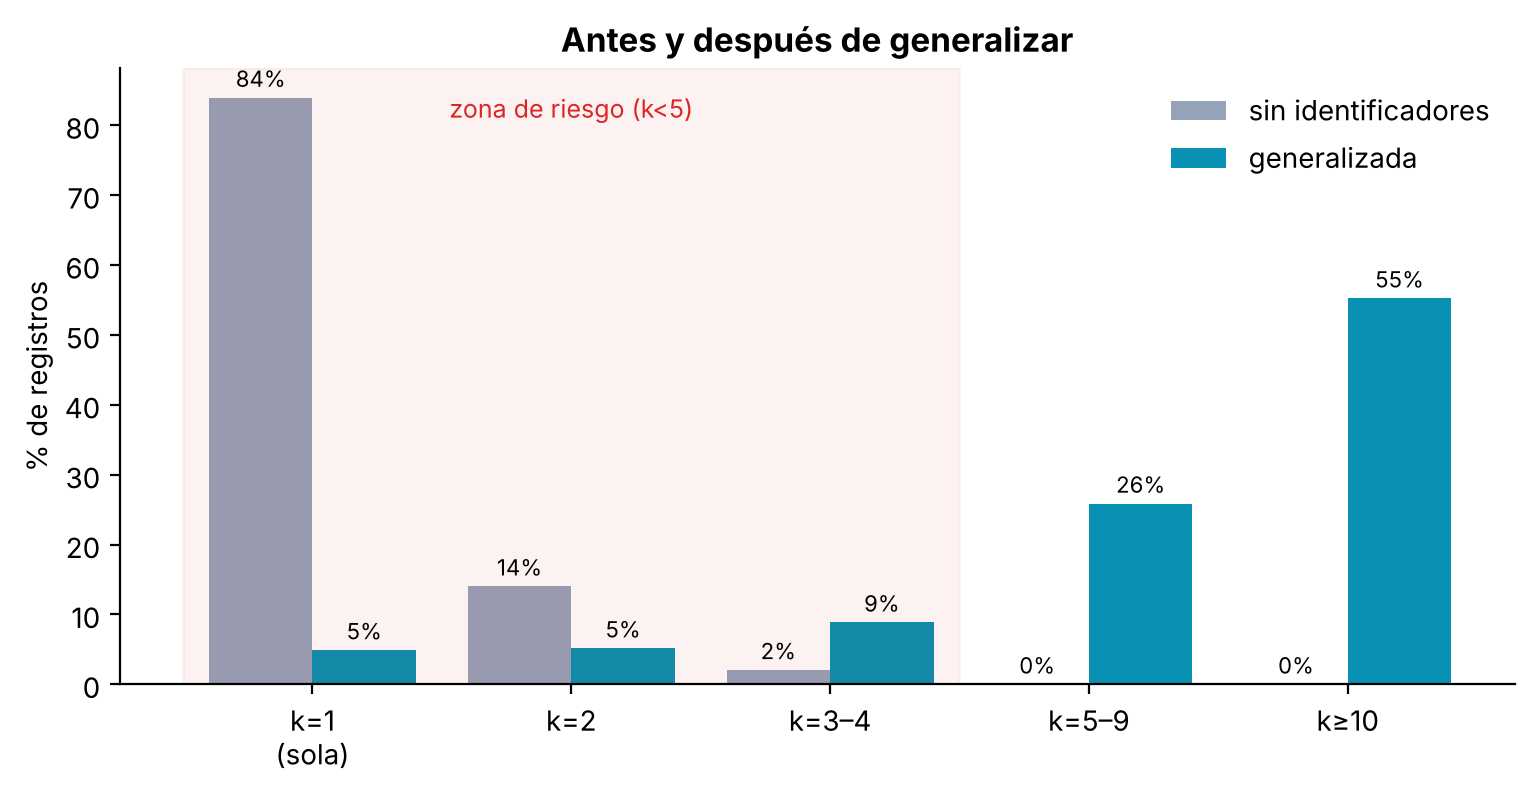

In [14]:
grafico_grupos({"sin identificadores": base_ingenua, "generalizada": e3},
               titulo="Antes y después de generalizar")

### Todas las combinaciones de una vez

En lugar de probar a mano, recorramos las 108 combinaciones de perillas y
veamos dónde quedan. Cada punto es una versión posible de la base.

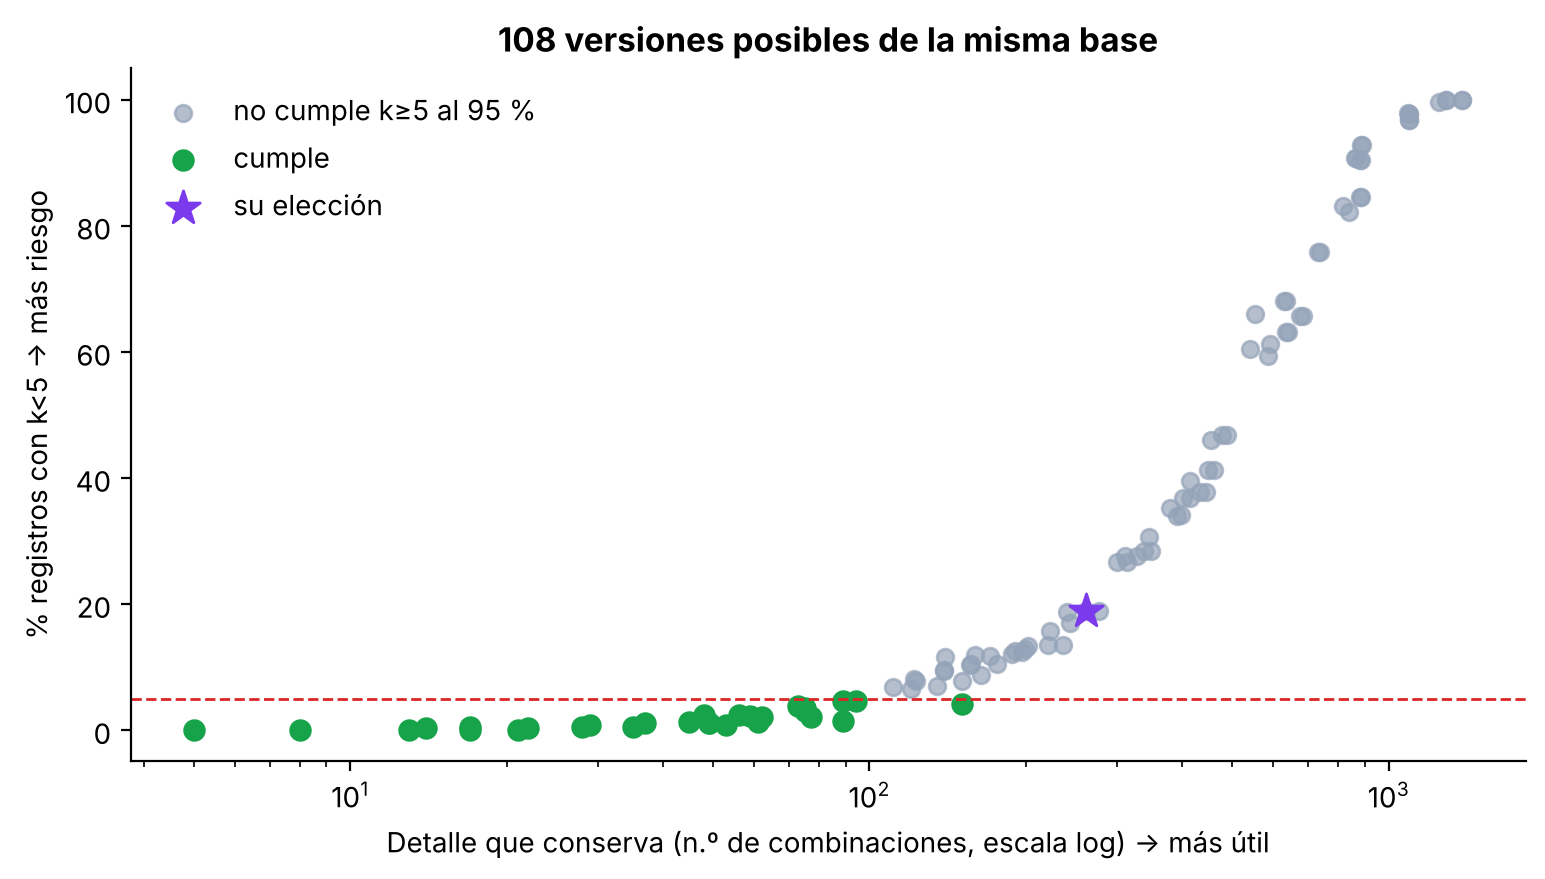

Las cinco versiones que cumplen con MÁS detalle:


,edad,sexo,ciudad,ocupacion,% k<5,combinaciones,% homogéneos (k≥2)
51,5,suprimir,suprimir,exacta,4.2,151,0.1
68,10,agrupar,region,suprimir,4.6,94,0.1
61,10,conservar,suprimir,grupo,4.7,89,0.0
78,10,suprimir,suprimir,exacta,1.5,89,0.1
74,10,suprimir,ciudad,suprimir,2.1,77,0.2


In [15]:
import itertools

filas = []
for ed, sx, ci, oc in itertools.product([0, 5, 10, 20], ["conservar", "agrupar", "suprimir"],
                                        ["ciudad", "region", "suprimir"], ["exacta", "grupo", "suprimir"]):
    g = generalizar(e1, ed, sx, ci, oc)
    p = perfil_riesgo(g)
    # Utilidad sencilla: cuánto detalle conserva (combinaciones posibles, en escala log).
    filas.append({"edad": ed, "sexo": sx, "ciudad": ci, "ocupacion": oc,
                  "% k<5": p["% k<5"], "combinaciones": p["combinaciones"],
                  "% homogéneos (k≥2)": p["% homogéneos (k≥2)"]})
mapa = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(9, 4.5))
ok = mapa["% k<5"] < 5
ax.scatter(mapa.loc[~ok, "combinaciones"], mapa.loc[~ok, "% k<5"], color=COLOR["antes"], alpha=.7, label="no cumple k≥5 al 95 %")
ax.scatter(mapa.loc[ok, "combinaciones"], mapa.loc[ok, "% k<5"], color=COLOR["ok"], s=50, label="cumple")
mia = perfil_riesgo(e3)
ax.scatter([mia["combinaciones"]], [mia["% k<5"]], color=COLOR["acento"], s=160, marker="*", label="su elección", zorder=5)
ax.axhline(5, color=COLOR["alerta"], ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Detalle que conserva (n.º de combinaciones, escala log) → más útil")
ax.set_ylabel("% registros con k<5 → más riesgo")
ax.set_title("108 versiones posibles de la misma base")
ax.legend(frameon=False)
plt.show()

print("Las cinco versiones que cumplen con MÁS detalle:")
mapa[ok].sort_values("combinaciones", ascending=False).head(5)

#### 🎮 Panel interactivo (Colab o Jupyter)

Si está en Colab o Jupyter con `ipywidgets`, la celda siguiente crea un panel
con menús. Si no, muestra una tabla fija. Funciona igual en los dos casos.

In [16]:
def panel(edad=10, sexo="agrupar", ciudad="region", ocupacion="grupo"):
    g = generalizar(e1, edad, sexo, ciudad, ocupacion)
    p = perfil_riesgo(g)
    semaforo = "🟢" if p["% k<5"] < 5 else ("🟡" if p["% k<5"] < 20 else "🔴")
    print(f"{semaforo}  k mínimo {p['k mínimo']}  ·  {p['% k<5']} % en k<5  ·  "
          f"{p['% homogéneos (k≥2)']} % en grupos homogéneos  ·  {p['combinaciones']} combinaciones")

try:
    from ipywidgets import interact
    interact(panel, edad=[0, 5, 10, 20], sexo=["conservar", "agrupar", "suprimir"],
             ciudad=["ciudad", "region", "suprimir"], ocupacion=["exacta", "grupo", "suprimir"])
except ImportError:
    for ed in [0, 5, 10, 20]:
        print(f"edad={ed:>2}", end="  ")
        panel(ed)

edad= 0  🔴  k mínimo 1  ·  90.5 % en k<5  ·  4.6 % en grupos homogéneos  ·  881 combinaciones
edad= 5  🔴  k mínimo 1  ·  36.9 % en k<5  ·  1.4 % en grupos homogéneos  ·  402 combinaciones
edad=10  🟡  k mínimo 1  ·  18.9 % en k<5  ·  0.9 % en grupos homogéneos  ·  261 combinaciones
edad=20  🟡  k mínimo 1  ·  11.8 % en k<5  ·  0.7 % en grupos homogéneos  ·  171 combinaciones


> ### 🟡 Decida · Pregunta 5
>
> En el gráfico de las 108 versiones, ¿qué perilla baja más el riesgo por cada unidad de detalle que se pierde? ¿Y cuál es la que **menos** le conviene tocar si el proveedor necesita recomendar por ciudad?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

La edad es la variable con más valores (65), así que pasar de edad exacta a rangos de 10 años es la palanca más eficiente. Si la finalidad exige ciudad, se conserva ciudad y se compensa con más generalización en edad u ocupación. La lección: **la finalidad decide qué variable se sacrifica**, no la comodidad técnica.

</details>

**Mi respuesta:** …

## 🧰 Estación 4 · Supresión local: quitar a los que quedan solos

Después de generalizar suele quedar un puñado de personas en grupos pequeños.
Una salida es **suprimir esos registros**. Parece gratis. No lo es.

In [17]:
tam = tam_grupo(e3, CUASI)
e4 = e3[tam >= K_OBJETIVO].copy()
suprimidos = e3[tam < K_OBJETIVO]

print(f"Registros suprimidos: {len(suprimidos)} ({len(suprimidos)/len(e3)*100:.1f} %)")
registrar("4 · + supresión local k<5", e4, "supresión de registros",
          nota=f"{len(suprimidos)} registros fuera")

Registros suprimidos: 286 (18.9 %)


,técnica,registros,combinaciones,k mínimo,% k=1,% k<5,prob. media reid. %,l mínimo,% homogéneos (k≥2),nota
paso,,,,,,,,,,
0 · sin identificadores directos,supresión de 5 columnas,1512,1385,1,83.9,100.0,91.6,1,3.2,lo que casi todos entregan
3 · generalización (mía),generalización,1512,261,1,4.9,18.9,17.3,1,0.9,edad 10 · sexo agrupar · region · ocupación grupo
4 · + supresión local k<5,supresión de registros,1226,109,5,0.0,0.0,8.9,3,0.0,286 registros fuera


In [18]:
# ¿Los suprimidos son una muestra al azar? Comparemos.
comparacion = pd.DataFrame({
    "se quedan": [e4["churn"].mean(), (e4["sexo"].isin(["Otro", "Otro/NR", "Prefiere no responder"])).mean(),
                  (e4["pais_residencia"] != "Colombia").mean(), e4["edad"].astype(str).str[:2].isin(["60", "70", "80"]).mean()],
    "se suprimen": [suprimidos["churn"].mean(), (suprimidos["sexo"].isin(["Otro", "Otro/NR", "Prefiere no responder"])).mean(),
                    (suprimidos["pais_residencia"] != "Colombia").mean(), suprimidos["edad"].astype(str).str[:2].isin(["60", "70", "80"]).mean()],
}, index=["tasa de abandono", "sexo: otro / no responde", "residente fuera de Colombia", "60 años o más"]) * 100
comparacion.round(1).style.format("{:.1f} %").background_gradient(axis=1, cmap="Reds")

,se quedan,se suprimen
tasa de abandono,27.7 %,27.3 %
sexo: otro / no responde,0.4 %,29.7 %
residente fuera de Colombia,10.1 %,8.7 %
60 años o más,2.4 %,18.5 %


> ### 🔴 Riesgo · Pregunta 6
>
> ¿A quién se lleva la supresión? Si el proveedor entrena con la base sin esas personas, ¿para quién va a funcionar peor el recomendador?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

La supresión se lleva sobre todo a las minorías de la base: personas que no se identifican como F o M, mayores, residentes fuera del país. Proteger su identidad borrándolas las vuelve **invisibles** para el modelo: es un sesgo de representación fabricado por la anonimización (enlace directo con el Encuentro 3). Alternativa: suprimir celdas (reemplazar por `*`) en lugar de filas, o generalizar más solo para esos grupos.

</details>

**Mi respuesta:** …

## 🧰 Estación 5 · *Top coding* y microagregación

Los ingresos tienen una cola larga: una persona que gana 22 millones es casi
única aunque todo lo demás esté generalizado.

- ***Top/bottom coding***: todo lo que pase del percentil 95 se registra como el percentil 95.
- **Microagregación**: se ordena, se forman grupos de *k* personas y se reemplaza el valor por el promedio del grupo.

In [19]:
def top_bottom(s, inf=0.05, sup=0.95):
    return s.clip(s.quantile(inf), s.quantile(sup))

def microagregar(s, k=K_OBJETIVO):
    s = s.copy()
    validos = s.dropna().sort_values()
    grupo = np.arange(len(validos)) // k
    grupo[grupo == grupo.max()] = max(grupo.max() - 1, 0) if (grupo == grupo.max()).sum() < k else grupo.max()
    s.loc[validos.index] = validos.groupby(grupo).transform("mean").values
    return s

ingresos = e4["ingresos_mensuales"]
versiones_ing = pd.DataFrame({
    "original": ingresos,
    "top/bottom 5 %": top_bottom(ingresos),
    "microagregado k=5": microagregar(ingresos),
})

resumen = versiones_ing.agg(["mean", "median", "std", "max", "nunique"]).T
resumen.columns = ["media", "mediana", "desv. est.", "máximo", "valores distintos"]
resumen.style.format("{:,.0f}")

,media,mediana,desv. est.,máximo,valores distintos
original,"3,477,676","2,775,000","2,470,116","22,410,000",520
top/bottom 5 %,"3,358,591","2,775,000","2,016,334","8,371,000",441
microagregado k=5,"3,477,676","2,772,000","2,462,937","18,294,000",222


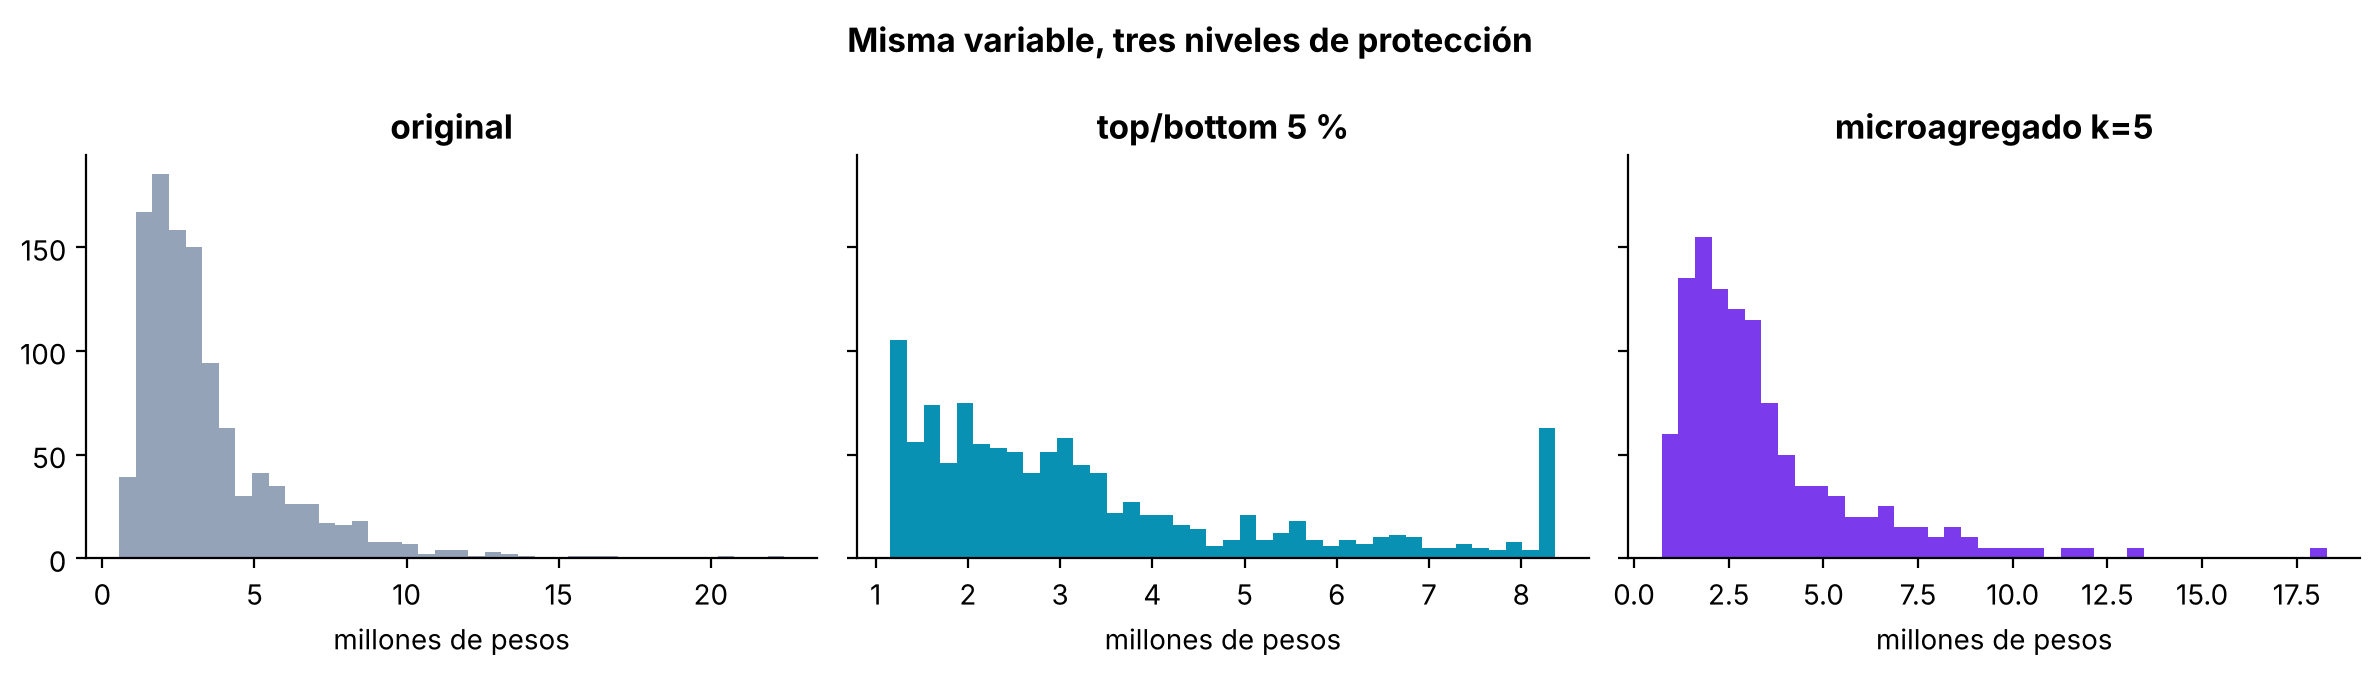

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, (nombre, serie), col in zip(ax, versiones_ing.items(), [COLOR["antes"], COLOR["despues"], COLOR["acento"]]):
    a.hist(serie.dropna() / 1e6, bins=40, color=col)
    a.set_title(nombre)
    a.set_xlabel("millones de pesos")
plt.suptitle("Misma variable, tres niveles de protección", fontweight="bold")
plt.tight_layout()
plt.show()

> ### 🟡 Decida · Pregunta 7
>
> La microagregación conserva la media **exactamente**. ¿Qué no conserva? Y si el proveedor quisiera estudiar a los clientes de ingresos más altos, ¿cuál de las dos técnicas le haría más daño?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Conserva la media pero reduce la varianza y la cantidad de valores distintos, y debilita correlaciones con otras variables. El *top coding* destruye la cola superior: si el interés está justamente en los clientes de mayores ingresos, es la técnica que más daño hace.

</details>

**Mi respuesta:** …

## 🧰 Estación 6 · Perturbación: ruido y coordenadas

Alterar valores de forma controlada. Útil para variables continuas que el
proveedor necesita en escala numérica.

In [21]:
# ===================== PERILLA =====================
RUIDO_MONTO = 0.10      # desviación relativa del ruido multiplicativo (0.10 = ±10 %)
DECIMALES_COORD = 2     # 4 ≈ 11 m · 3 ≈ 110 m · 2 ≈ 1,1 km · 1 ≈ 11 km
# ===================================================
rng = np.random.default_rng(11)
monto_ruido = df["monto_compras"] * (1 + rng.normal(0, RUIDO_MONTO, len(df)))

print(f"Media del monto   original: {df['monto_compras'].mean():>12,.0f}   con ruido: {monto_ruido.mean():>12,.0f}")
print(f"Correlación monto-compras_6m original: {df['monto_compras'].corr(df['compras_6m']):.3f}"
      f"   con ruido: {monto_ruido.corr(df['compras_6m']):.3f}")

coords = df[["latitud", "longitud"]]
coords_r = coords.round(DECIMALES_COORD)
print(f"\nPuntos distintos con coordenadas originales: {len(coords.drop_duplicates()):,}")
print(f"Puntos distintos con {DECIMALES_COORD} decimales            : {len(coords_r.drop_duplicates()):,}")
k_coord = tam_grupo(coords_r.assign(barrio=df["barrio"]), ["latitud", "longitud", "barrio"])
print(f"Personas solas en su punto + barrio      : {(k_coord == 1).mean()*100:.1f} %")

Media del monto   original:      364,989   con ruido:      365,530
Correlación monto-compras_6m original: 0.661   con ruido: 0.659

Puntos distintos con coordenadas originales: 1,500
Puntos distintos con 2 decimales            : 712
Personas solas en su punto + barrio      : 58.8 %


> ### 🔵 Pruebe · Pregunta 8
>
> Pruebe `DECIMALES_COORD = 1` y `= 3`. ¿Cuántos decimales necesita para que menos del 20 % quede solo en su punto? ¿Le sirve todavía al proveedor una coordenada así, o es mejor entregar solo la región?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Con 3 decimales (≈ 110 m) y el barrio, el 97,6 % queda solo; con 2 (≈ 1 km), el 58,8 %; con 1 decimal (≈ 11 km), el 1,8 %, pero el punto ya equivale casi a la ciudad. A ese nivel la coordenada no aporta nada que la región no dé: es más honesto suprimirla. Además, el ruido de ±3 km que ya tenían los datos **no** las hacía anónimas, como advierte la Actividad 4.

</details>

**Mi respuesta:** …

## 🧰 Estación 7 · Privacidad diferencial para tablas

Cuando lo que se publica son **conteos** (un tablero, un informe), se puede
sumar ruido calibrado con una garantía matemática. El parámetro **ε (épsilon)**
es el *presupuesto de privacidad*: menor ε, más ruido, más protección.

El mecanismo de Laplace: `conteo publicado = conteo real + Laplace(0, 1/ε)`.
Es la técnica que usó la Oficina del Censo de Estados Unidos para el censo de 2020.

In [22]:
# Pregunta que alguien quiere publicar: ¿cuántos clientes compran sobre todo salud o maternidad, por ciudad?
real = (df.assign(sensible=df["categoria_top"].isin(["salud_bienestar", "bebe_maternidad"]))
          .groupby("ciudad")["sensible"].sum().sort_values())

def laplace(conteos, epsilon, semilla=0):
    r = np.random.default_rng(semilla)
    return (conteos + r.laplace(0, 1 / epsilon, len(conteos))).round().clip(lower=0).astype(int)

tabla_dp = pd.DataFrame({"real": real})
for eps in [0.1, 0.5, 1, 5]:
    tabla_dp[f"ε = {eps}"] = laplace(real, eps).values
tabla_dp

,real,ε = 0.1,ε = 0.5,ε = 1,ε = 5
ciudad,,,,,
Manizales,6,9,7,6,6
Pasto,6,0,5,5,6
Santa Marta,9,0,4,6,8
Ibague,9,0,2,6,8
Bucaramanga,12,22,14,13,12
Cartagena,13,30,16,15,13
Pereira,15,17,15,15,15
Villavicencio,20,26,21,21,20
Cali,23,24,23,23,23


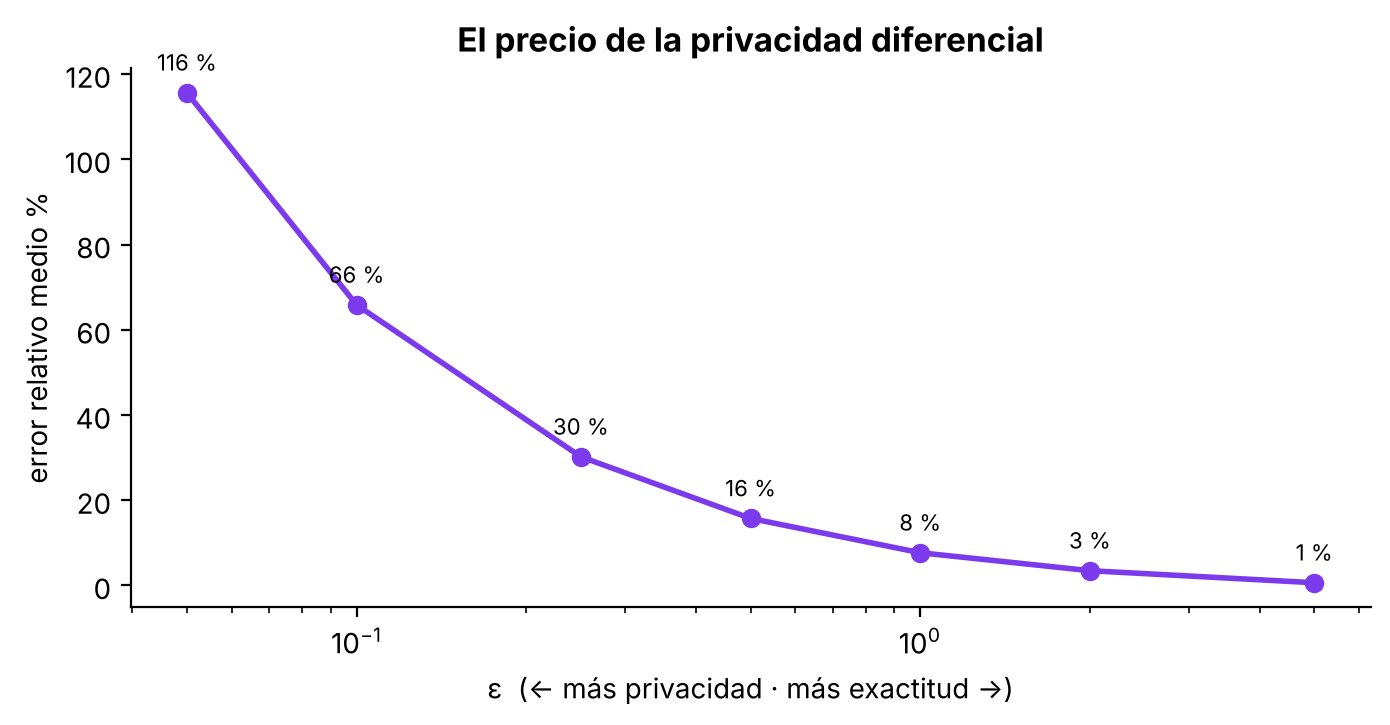

In [23]:
# Error relativo promedio según ε, repitiendo 200 publicaciones.
eps_grid = [0.05, 0.1, 0.25, 0.5, 1, 2, 5]
errores = []
for eps in eps_grid:
    e = [np.mean(np.abs(laplace(real, eps, s) - real) / real) * 100 for s in range(200)]
    errores.append(np.mean(e))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(eps_grid, errores, "o-", color=COLOR["acento"], lw=2)
ax.set_xscale("log")
ax.set_xlabel("ε  (← más privacidad · más exactitud →)")
ax.set_ylabel("error relativo medio %")
ax.set_title("El precio de la privacidad diferencial")
for x, y in zip(eps_grid, errores):
    ax.annotate(f"{y:.0f} %", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.show()

> ### 🟡 Decida · Pregunta 9
>
> Para la ciudad más pequeña el error relativo es mucho mayor que para Bogotá con el mismo ε. ¿Por qué? ¿Qué le dice eso sobre publicar tablas muy desagregadas (por barrio, por vereda)?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

El ruido de Laplace tiene el mismo tamaño absoluto para todas las celdas; en una celda pequeña ese ruido pesa mucho más en términos relativos. Mientras más se desagrega, más ruido relativo, y cada consulta adicional consume presupuesto. Desagregar tiene un precio que se paga en exactitud o en privacidad, no hay tercera opción.

</details>

**Mi respuesta:** …

## 🧰 Estación 8 · Datos sintéticos

Generar una base **nueva**, sin personas reales, que imite a la original.
Probamos dos generadores muy sencillos y los evaluamos con la prueba estándar:
**entrenar con sintético y evaluar con real** (TSTR).

In [24]:
COLS_MODELO = ["edad", "sexo", "ciudad", "ocupacion", "estrato", "visitas_web", "productos_vistos",
               "compras_6m", "monto_compras", "recencia_dias", "canal_adquisicion", "categoria_top"]

def sintetico_independiente(datos, columnas, n=None, semilla=1):
    # Cada columna se muestrea por separado: conserva marginales, rompe relaciones.
    r = np.random.default_rng(semilla)
    n = n or len(datos)
    return pd.DataFrame({c: r.choice(datos[c].values, n) for c in columnas + ["churn"]})

def sintetico_condicional(datos, columnas, objetivo="churn", semilla=1):
    # Dentro de cada clase de churn, cada columna se muestrea por separado.
    partes = []
    for valor, sub in datos.groupby(objetivo):
        s = sintetico_independiente(sub, columnas, len(sub), semilla + int(valor))
        s[objetivo] = valor
        partes.append(s)
    return pd.concat(partes, ignore_index=True).sample(frac=1, random_state=semilla)

def tstr(sintetico, real, columnas):
    Xs = pd.get_dummies(sintetico[columnas], dtype=float)
    Xr = pd.get_dummies(real[columnas], dtype=float).reindex(columns=Xs.columns, fill_value=0)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(Xs, sintetico["churn"])
    from sklearn.metrics import roc_auc_score
    return round(roc_auc_score(real["churn"], m.predict_proba(Xr)[:, 1]), 3)

real_mod = df[COLS_MODELO + ["churn"]].dropna()
s_ind = sintetico_independiente(real_mod, COLS_MODELO)
s_con = sintetico_condicional(real_mod, COLS_MODELO)

copias = s_con.merge(real_mod, on=COLS_MODELO + ["churn"]).shape[0]
utilidad_sint = pd.DataFrame({
    "AUC (evaluado en datos reales)": [auc_churn(real_mod, COLS_MODELO), tstr(s_ind, real_mod, COLS_MODELO),
                                       tstr(s_con, real_mod, COLS_MODELO)],
}, index=["modelo entrenado con datos reales", "sintético independiente", "sintético condicional"])
print(f"Filas sintéticas idénticas a una persona real: {copias}")
utilidad_sint

Filas sintéticas idénticas a una persona real: 0


,AUC (evaluado en datos reales)
modelo entrenado con datos reales,0.824
sintético independiente,0.643
sintético condicional,0.820


> ### 🔴 Riesgo · Pregunta 10
>
> El sintético independiente pierde casi toda la señal; el condicional conserva parte. Un generador más potente (redes neuronales, cópulas) conservaría más… ¿y qué riesgo nuevo aparece cuando un generador es **demasiado bueno**?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Que **memorice**: un generador muy ajustado puede reproducir registros reales casi idénticos, sobre todo de personas atípicas. Por eso un sintético no es anónimo por definición: hay que medir copias exactas, distancia al registro real más cercano y ataques de pertenencia. Es el mismo problema de los modelos de lenguaje que memorizan datos de entrenamiento (parte 6).

</details>

**Mi respuesta:** …

---

# 4 · COMPARAR

*Cuatro bases candidatas, dos ejes: riesgo y utilidad. Y el ataque otra vez.*

In [25]:
COLS_ENTREGA = COLS_MODELO + ["churn"]

candidatas = {
    "V0 · sin identificadores": e1,
    "V1 · generalización suave": generalizar(e1, 5, "conservar", "ciudad", "grupo"),
    "V2 · generalización fuerte + supresión": None,
    "V3 · sintética condicional": s_con,
}
v2 = generalizar(e1, 10, "agrupar", "region", "grupo")
candidatas["V2 · generalización fuerte + supresión"] = v2[tam_grupo(v2, CUASI) >= K_OBJETIVO]
candidatas["★ su versión (estaciones 3+4)"] = e4

filas = []
for nombre, base in candidatas.items():
    p = perfil_riesgo(base)
    if nombre.startswith("V3"):
        # En una base sintética no hay personas reales que acertar: k no aplica.
        p = {k_: np.nan for k_ in p}
        reid, auc = 0.0, tstr(base, real_mod, COLS_MODELO)
    else:
        pub = fuente_publica.copy()
        if base is not e1:   # el atacante conoce el esquema de generalización y lo aplica
            ref = {"V1": (5, "conservar", "ciudad", "grupo"), "V2": (10, "agrupar", "region", "grupo"),
                   "★ ": (NIVEL_EDAD, SEXO_COMO, CIUDAD_COMO, OCUPACION_COMO)}[nombre[:2]]
            pub = generalizar(pub, *ref)
        reid = ataque_vinculacion(pub, base, CUASI, mostrar=False)[0]["% reidentificadas"]
        auc = auc_churn(base, COLS_MODELO)
    filas.append({"versión": nombre, "registros": len(base), "% k<5": p["% k<5"],
                  "prob. media reid. %": p["prob. media reid. %"],
                  "% reidentificadas en el ataque": reid, "AUC": auc})

frontera = pd.DataFrame(filas).set_index("versión")
frontera

,registros,% k<5,prob. media reid. %,% reidentificadas en el ataque,AUC
versión,,,,,
V0 · sin identificadores,1512,100.0,91.6,82.7,0.823
V1 · generalización suave,1512,63.2,42.4,21.0,0.818
V2 · generalización fuerte + supresión,1226,0.0,8.9,0.0,0.825
V3 · sintética condicional,1378,NaN,NaN,0.0,0.820
★ su versión (estaciones 3+4),1226,0.0,8.9,0.0,0.825


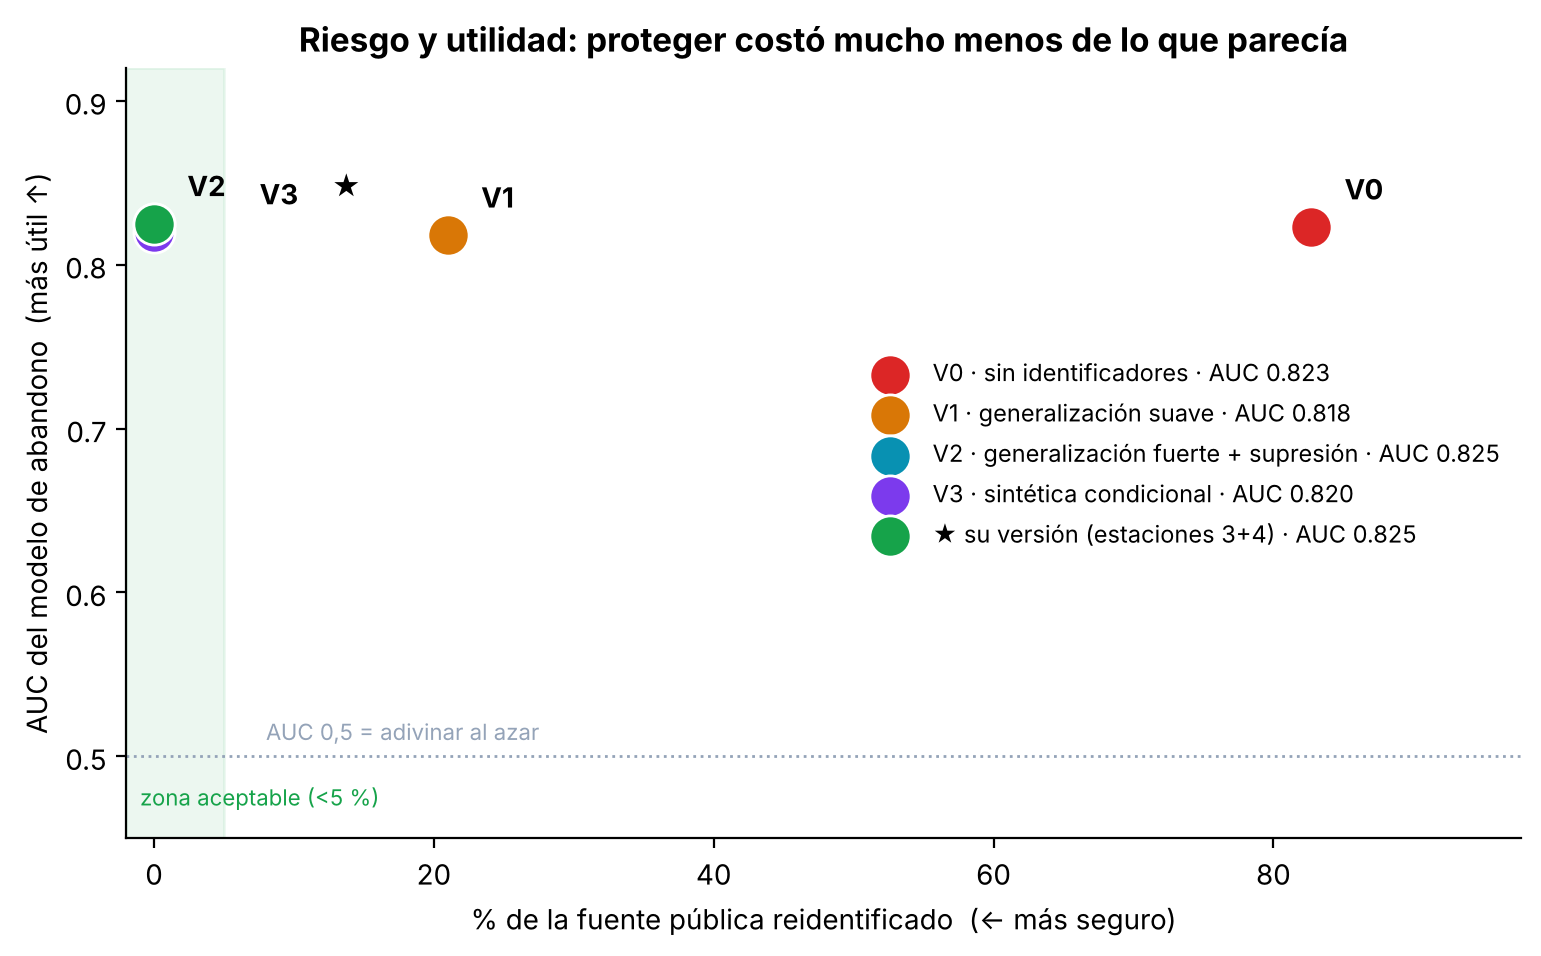

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))
colores = [COLOR["alerta"], COLOR["ambar"], COLOR["despues"], COLOR["acento"], COLOR["ok"]]
usados = {}
for (nombre, fila), col in zip(frontera.iterrows(), colores):
    x, y = fila["% reidentificadas en el ataque"], fila["AUC"]
    ax.scatter(x, y, s=220, color=col, zorder=3, edgecolor="white", label=f"{nombre} · AUC {y:.3f}")
    clave = round(x / 5)
    desfase = usados.get(clave, 0)
    usados[clave] = desfase + 1
    ax.annotate(nombre.split(" · ")[0].replace("★ su versión (estaciones 3+4)", "★"), (x, y),
                textcoords="offset points", xytext=(12 + 26 * desfase, 10), fontsize=10, fontweight="bold")
ax.axhline(0.5, color=COLOR["antes"], ls=":", lw=1)
ax.text(8, 0.51, "AUC 0,5 = adivinar al azar", fontsize=8, color=COLOR["antes"])
ax.set_ylim(0.45, 0.92)
ax.axvspan(-2, 5, color=COLOR["ok"], alpha=.08)
ax.text(-1, 0.47, "zona aceptable (<5 %)", fontsize=8, color=COLOR["ok"])
ax.set_xlabel("% de la fuente pública reidentificado  (← más seguro)")
ax.set_ylabel("AUC del modelo de abandono  (más útil ↑)")
ax.set_title("Riesgo y utilidad: proteger costó mucho menos de lo que parecía")
ax.set_xlim(-2, max(frontera["% reidentificadas en el ataque"]) + 15)
ax.legend(frameon=False, loc="center right", fontsize=8.5)
plt.show()

> ### 🟣 Decisión · Pregunta 11
>
> Mire el gráfico. ¿Cuánta utilidad (AUC) se pierde al pasar de V0 a V2? ¿Y cuánto riesgo se gana?
>
> La pregunta central del encuentro: **¿cuánta utilidad estamos dispuestos a perder, y quién decide eso?**

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

En esta base la pérdida de AUC entre V0 y V2 es prácticamente nula (del orden de milésimas, incluso puede subir), porque el abandono depende sobre todo del comportamiento y no de la demografía, mientras que el porcentaje reidentificado cae de forma drástica. Es un hallazgo importante: **muchas veces la protección cuesta menos de lo que se teme**, pero solo se sabe si se mide. Quién decide: no el analista solo; el responsable del tratamiento, con el umbral escrito y firmado.

</details>

**Mi respuesta:** …

---

# 5 · DECIDIR Y ENTREGAR

*Una base concreta, un umbral escrito y un informe que otra persona pueda auditar.*

In [27]:
pd.DataFrame(BITACORA).set_index("paso")

,técnica,registros,combinaciones,k mínimo,% k=1,% k<5,prob. media reid. %,l mínimo,% homogéneos (k≥2),nota
paso,,,,,,,,,,
0 · sin identificadores directos,supresión de 5 columnas,1512,1385,1,83.9,100.0,91.6,1,3.2,lo que casi todos entregan
3 · generalización (mía),generalización,1512,261,1,4.9,18.9,17.3,1,0.9,edad 10 · sexo agrupar · region · ocupación grupo
4 · + supresión local k<5,supresión de registros,1226,109,5,0.0,0.0,8.9,3,0.0,286 registros fuera


In [28]:
# ===================== PERILLA =====================
VERSION_ELEGIDA = "V2 · generalización fuerte + supresión"
SALIDA = "1 · base anonimizada con utilidad reducida"
UMBRAL = "k ≥ 5 para el 100 % de los registros y <5 % de la fuente pública reidentificada"
JUSTIFICACION = ("El abandono depende del comportamiento, no de la demografía fina: "
                 "V2 conserva casi todo el AUC y reduce el ataque de vinculación a casi cero.")
CONDICIONES = ("Acuerdo de transmisión con prohibición de cruce y de reidentificación; "
               "uso exclusivo para el motor de recomendación; destrucción a los 6 meses; auditoría.")
EQUIPO = "Docente · versión de referencia"
# ===================================================

In [29]:
entregable = candidatas[VERSION_ELEGIDA][[c for c in COLS_ENTREGA if c in candidatas[VERSION_ELEGIDA].columns]].copy()
entregable.insert(0, "id_seudo", [secrets.token_hex(6) for _ in range(len(entregable))])  # sin vínculo posible
entregable.to_csv("base_entregable_proveedor.csv", index=False, encoding="utf-8")

f = frontera.loc[VERSION_ELEGIDA]
informe = f'''# Informe de riesgo de reidentificación · DataMarket → proveedor

**Equipo:** {EQUIPO}  ·  **Fecha:** {pd.Timestamp("today").date()}

## 1. Qué se entrega
- Versión: **{VERSION_ELEGIDA}** · salida elegida: **{SALIDA}**
- {len(entregable):,} registros de {len(df):,} · {entregable.shape[1]} variables: {", ".join(entregable.columns)}

## 2. Qué se midió (escenario: el atacante conoce edad, sexo, ciudad y ocupación)
| Métrica | Línea base (V0) | Entregable |
|:--|--:|--:|
| % registros con k<5 | {frontera.iloc[0]["% k<5"]} | {f["% k<5"]} |
| Prob. media de reidentificación % | {frontera.iloc[0]["prob. media reid. %"]} | {f["prob. media reid. %"]} |
| % reidentificado en el ataque | {frontera.iloc[0]["% reidentificadas en el ataque"]} | {f["% reidentificadas en el ataque"]} |
| AUC del modelo de abandono | {frontera.iloc[0]["AUC"]} | {f["AUC"]} |

## 3. Umbral aceptado y por qué
{UMBRAL}. {JUSTIFICACION}

## 4. Riesgo residual
Vale para el escenario declarado. No cubre atacantes con información adicional
(compras exactas, fechas) ni el cruce con otras bases del proveedor.

## 5. Condiciones de la entrega
{CONDICIONES}
'''
with open("informe_anonimizacion.md", "w", encoding="utf-8") as fh:
    fh.write(informe)

from IPython.display import Markdown, display
display(Markdown(informe))
print("Archivos creados: base_entregable_proveedor.csv · informe_anonimizacion.md")

# Informe de riesgo de reidentificación · DataMarket → proveedor

**Equipo:** Docente · versión de referencia  ·  **Fecha:** 2026-11-10

## 1. Qué se entrega
- Versión: **V2 · generalización fuerte + supresión** · salida elegida: **1 · base anonimizada con utilidad reducida**
- 1,226 registros de 1,512 · 14 variables: id_seudo, edad, sexo, ciudad, ocupacion, estrato, visitas_web, productos_vistos, compras_6m, monto_compras, recencia_dias, canal_adquisicion, categoria_top, churn

## 2. Qué se midió (escenario: el atacante conoce edad, sexo, ciudad y ocupación)
| Métrica | Línea base (V0) | Entregable |
|:--|--:|--:|
| % registros con k<5 | 100.0 | 0.0 |
| Prob. media de reidentificación % | 91.6 | 8.9 |
| % reidentificado en el ataque | 82.7 | 0.0 |
| AUC del modelo de abandono | 0.823 | 0.825 |

## 3. Umbral aceptado y por qué
k ≥ 5 para el 100 % de los registros y <5 % de la fuente pública reidentificada. El abandono depende del comportamiento, no de la demografía fina: V2 conserva casi todo el AUC y reduce el ataque de vinculación a casi cero.

## 4. Riesgo residual
Vale para el escenario declarado. No cubre atacantes con información adicional
(compras exactas, fechas) ni el cruce con otras bases del proveedor.

## 5. Condiciones de la entrega
Acuerdo de transmisión con prohibición de cruce y de reidentificación; uso exclusivo para el motor de recomendación; destrucción a los 6 meses; auditoría.


Archivos creados: base_entregable_proveedor.csv · informe_anonimizacion.md


> ### 🟣 Decisión · Pregunta 12
>
> El informe dice «riesgo residual: vale para el escenario declarado». Nombre **un escenario de ataque** que su medición no cubre y diga qué condición contractual o técnica lo compensaría.

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Ejemplos: el proveedor tiene su propia base de clientes con edad y ciudad exactas y compras con fecha (puede vincular por comportamiento, no por demografía) → prohibición contractual de cruce, auditoría y ambiente controlado. O una filtración en el proveedor → cifrado, acceso por rol y plazo de destrucción. Lo que se busca es que el estudiante reconozca que la métrica depende del escenario.

</details>

**Mi respuesta:** …

---

# 6 · REFLEXIONAR

*Lo que cambia con el volumen y con los modelos.*

| Con Big Data… | Con IA… |
|:--|:--|
| Más variables = más cuasi-identificadores: la unicidad **crece**, no se diluye | El modelo entrenado puede **memorizar** y devolver datos personales |
| Las trazas (ubicación, compras, búsquedas) son únicas: 4 puntos de ubicación bastan para identificar al 95 % de las personas (de Montjoye, 2013) | Un **ataque de pertenencia** puede revelar si alguien estaba en el entrenamiento |
| Cada cruce nuevo es un ataque de vinculación potencial | El modelo pasa a ser un **activo que contiene datos** y hereda sus obligaciones |

> ### 🟢 Reflexione · Pregunta 13
>
> El proveedor no quiere la base: quiere **entrenar un modelo** con ella. Si entrega V0 y él entrena un modelo muy grande, ¿la base deja de importar cuando se borra? ¿Qué pediría en el contrato sobre el **modelo**, no solo sobre los datos?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

No: el modelo puede conservar información de las personas y exponerla. En el contrato: uso exclusivo del modelo para la finalidad, prohibición de reutilizarlo o venderlo, destrucción o reentrenamiento si se revoca la autorización, pruebas de memorización antes del despliegue y la alternativa más fuerte: entrenar dentro del perímetro de DataMarket sin que los datos salgan.

</details>

**Mi respuesta:** …

> ### 🟢 Reflexione · Pregunta 14
>
> **Aporte al decálogo (Encuentro 5).** Escriba **una regla** para el decálogo del científico de datos que salga de este laboratorio.
>
> Formato: *verbo en imperativo + qué + evidencia que queda*. Ejemplo: «Mida el riesgo de reidentificación antes y después de transformar, y deje la bitácora con la entrega».

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Se busca una regla ejecutable y verificable. Otras buenas: «Ataque su base antes de entregarla»; «Nunca use un *hash* sin clave como seudónimo»; «Revise a quién se lleva la supresión».

</details>

**Mi respuesta:** …

---

## Lo que queda del laboratorio

| Archivo | Para qué |
|:--|:--|
| `base_entregable_proveedor.csv` | La base que saldría hacia el proveedor |
| `informe_anonimizacion.md` | El borrador del informe de la **Actividad 4** |
| La bitácora y la frontera riesgo-utilidad | La evidencia de que se midió |

### Las ocho técnicas en una línea

| Técnica | Protege | Cuesta |
|:--|:--|:--|
| Supresión de variables | Cierra puertas de vinculación | Todo el análisis que dependía de ellas |
| Seudonimización (HMAC) | El identificador | Nada… y **no anonimiza** |
| Generalización | Identidad (*k*) | Resolución analítica |
| Supresión local | Los casos raros | Sesgo: borra minorías |
| *Top coding* / microagregación | Valores extremos | Colas y varianza |
| Ruido | Valores exactos | Distribuciones y correlaciones |
| Privacidad diferencial | Tablas publicadas, con garantía | Exactitud en celdas pequeñas |
| Datos sintéticos | Todo, si no memoriza | Relaciones que el generador no captura |

**Siguiente paso:** Actividad 4 (en grupo, semana 8) y Encuentro 5 · el decálogo.

**Marco legal relacionado:** art. 10 de la Ley 1581 de 2012 (fines
estadísticos), considerando 26 del GDPR (datos anónimos frente a
seudonimizados), arts. 36 a 40 de la Ley 2335 de 2023 (reserva estadística).